до этого работали ток с координатами кафе но будем теперь работать не только с существующими кафе 

epsg:4326
MultiPolygon    1
Name: count, dtype: int64
(1, 17)


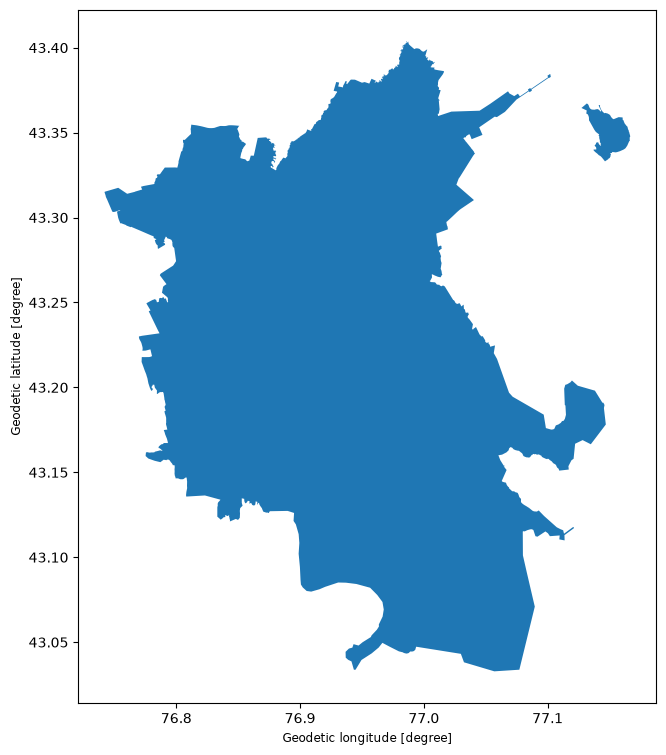

In [3]:
import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt

place = "Almaty, Kazakhstan"

almaty = ox.geocode_to_gdf(place) # получаем географическую границу из территории

print(almaty.crs) 
print(almaty.geometry.geom_type.value_counts())
print(almaty.shape)

almaty.plot(figsize=(9,9))
plt.show()

#получили географическую карту Алматы чтобы потом исключать ненужные нам регоины, по типу горы и тд
#мы получили территорию в градусах
#территория так же состоит из нескольких полигонов


In [4]:
# перевод границ в метры

metrics_crs = almaty.estimate_utm_crs()
almaty_m = almaty.to_crs(metrics_crs)

print(almaty_m.crs)

#перевели в метры


EPSG:32643


In [5]:
minX, minY, maxX, maxY = almaty_m.total_bounds

print(f'minX: {minX}')
print(f'minY: {minY}')
print(f'maxX: {maxX}')
print(f'maxY: {maxY}')

#создаются границы для создания прямоугольника который покрывает наш полигон
#а точнее карту Алмайти
#minX/minY - sleva, maxX/maxY - sprava

minX: 641265.5888651052
minY: 4766397.813012956
maxX: 675610.4805611279
maxY: 4807569.400086247


In [6]:
#np.arange() - создает последовательность чисел с определенным шагом

import numpy as np

x_coords = np.arange(minX, maxX, 500)
y_coords = np.arange(minY, maxY, 500)

In [7]:
from itertools import product

coordinates = list(product(x_coords, y_coords))

#Чтобы получить полноценную сетку, нужно составить все комбинации координат X и Y.

print(len(x_coords))
print(len(y_coords))
print(len(coordinates))

#теперь у нас 5727 потенциальных локаций


69
83
5727


In [8]:
from shapely.geometry import Point

# point = Point() # создает точки для каждой пары координат в нашем случае для 5727 пар

all_points_for_almaty = []

for i in range(len(coordinates)):
    
    point = Point(coordinates[i])
    all_points_for_almaty.append(point)


for i in range(5):
    print(all_points_for_almaty[i])

#точки созданы

POINT (641265.5888651052 4766397.813012956)
POINT (641265.5888651052 4766897.813012956)
POINT (641265.5888651052 4767397.813012956)
POINT (641265.5888651052 4767897.813012956)
POINT (641265.5888651052 4768397.813012956)


In [9]:
grid = gpd.GeoDataFrame(
    geometry=all_points_for_almaty,
    crs=almaty_m.crs)

print(grid.shape)
print(grid.crs)

(5727, 1)
EPSG:32643


In [10]:
#нужно сделать grid Almighty

city_geometry = almaty_m.geometry.iloc[0]

#происходит векторный цикл который спрашивает ячейка или point внутри алматы или не?
points_inside_city = grid[grid.geometry.within(city_geometry)]

print(len(points_inside_city))


2822


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

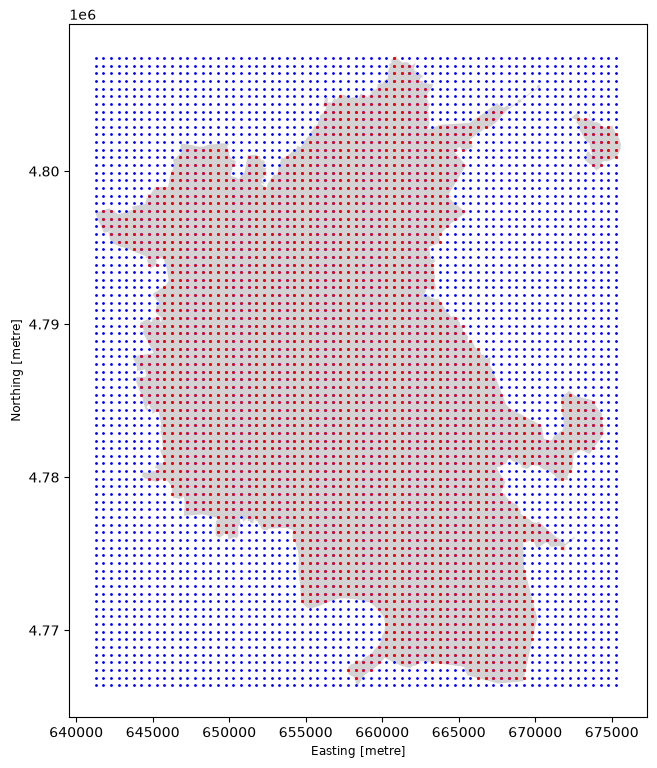

In [11]:
fig, ax = plt.subplots(figsize=(9,9))

almaty_m.plot(ax=ax, color='lightgray', markersize=9) # вся карта алматы

grid.plot(ax=ax, color='blue', markersize=1)

points_inside_city.plot(ax=ax, color='red', markersize=1)

In [ ]:
import geopandas as gpd

cafes_points = gpd.read_file(
    "../data/processed/cafes_points.gpkg"
)

print(cafes_points.shape)
print(cafes_points.crs)

points_inside_city.to_file(
    "../data/processed/candidate_locations.gpkg",
    driver="GPKG"
)

print(points_inside_city.crs)
print(cafes_points.crs)

(731, 118)
EPSG:32643
EPSG:32643
EPSG:32643


In [ ]:
#добавление функции count_nearby_cafes, чтобы потом я ее просто не копипастил раз за разом

import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root))

from src.spatial_features import count_nearby_cafes

candidate = points_inside_city.geometry.iloc[0]

result = count_nearby_cafes(
    candidate,
    cafes_points,
    radius=500
)

print(result)

0


In [25]:
#создаем точки(кафе) в датасет

cafes_counts = []

for point in points_inside_city.geometry:
    result = count_nearby_cafes(point, cafes_points, 500)
    cafes_counts.append(result)


print(len(cafes_counts))
print(cafes_counts[:10])

2822
[np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]


In [26]:
points_inside_city = points_inside_city.copy()

points_inside_city['cafes_500m'] = cafes_counts

In [27]:
points_inside_city['cafes_500m'].describe()

count    2822.000000
mean        0.813962
std         3.001673
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        42.000000
Name: cafes_500m, dtype: float64

In [30]:
print((points_inside_city['cafes_500m'] == 0).sum())
print((points_inside_city['cafes_500m'] > 0).sum())

2268
554


<Axes: >

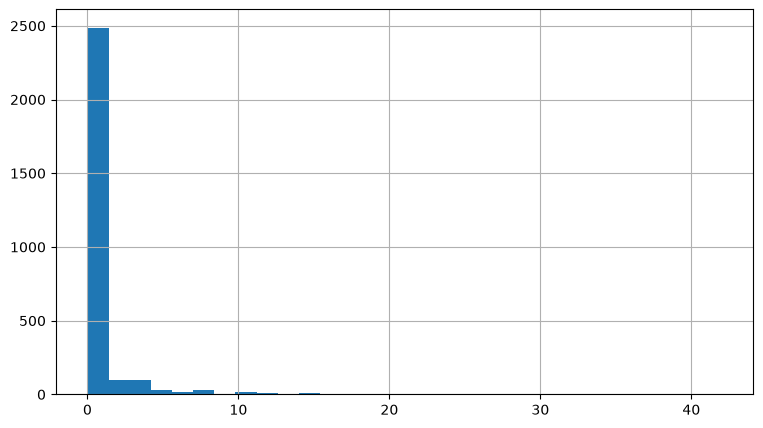

In [31]:
points_inside_city['cafes_500m'].hist(bins=30, figsize=(9,5))

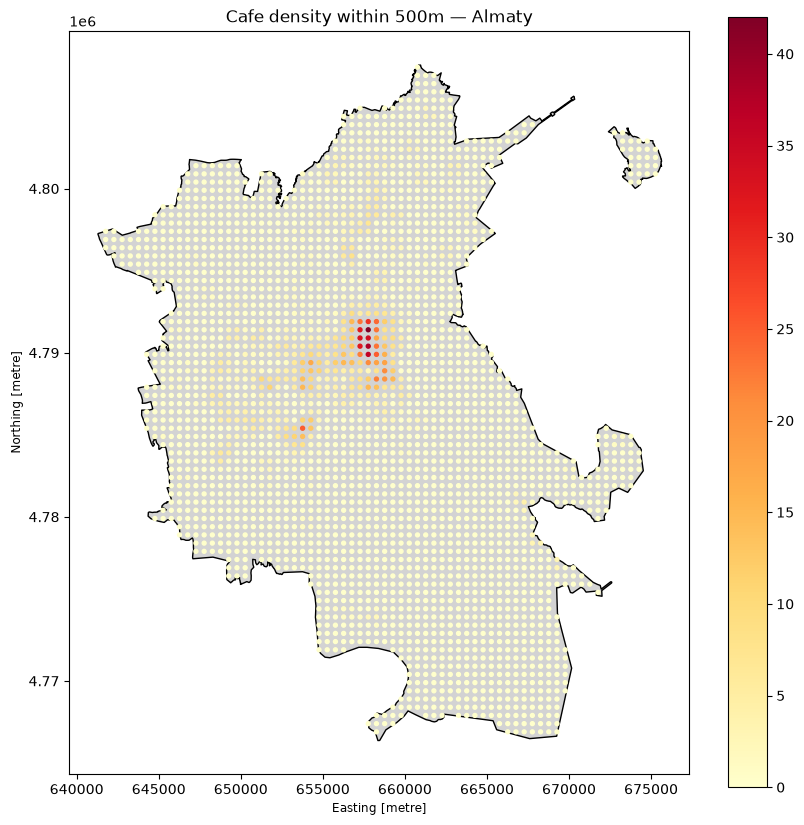

In [32]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,10))

almaty_m.plot(ax=ax, color='lightgray', edgecolor='k')

points_inside_city.plot(
    ax=ax,
    column="cafes_500m",
    cmap="YlOrRd",
    legend=True,
    markersize=8
)

ax.set_title("Cafe density within 500m — Almaty")
plt.show()

In [35]:
radius = [300, 500, 1000]


for radii in radius:

    cafes_counts = []

    for point in points_inside_city.geometry:

        result = count_nearby_cafes(point, cafes_points, radii)
        cafes_counts.append(result)

    points_inside_city[f'cafes_{radii}m'] = cafes_counts

In [42]:
points_inside_city['cafes_300m'].describe()

count    2822.000000
mean        0.282424
std         1.165787
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        19.000000
Name: cafes_300m, dtype: float64

In [43]:
points_inside_city['cafes_500m'].describe()

count    2822.000000
mean        0.813962
std         3.001673
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        42.000000
Name: cafes_500m, dtype: float64

In [44]:
points_inside_city['cafes_1000m'].describe()

count    2822.000000
mean        3.223600
std        10.091989
min         0.000000
25%         0.000000
50%         0.000000
75%         2.000000
max       116.000000
Name: cafes_1000m, dtype: float64

In [41]:
features = ['cafes_300m', 'cafes_500m', 'cafes_1000m']

for item in features:
    print(f'Feature name is {item}')
    print((points_inside_city[item] == 0).sum())
    print((points_inside_city[item] > 0).sum())
    print()

Feature name is cafes_300m
2501
321

Feature name is cafes_500m
2268
554

Feature name is cafes_1000m
1765
1057



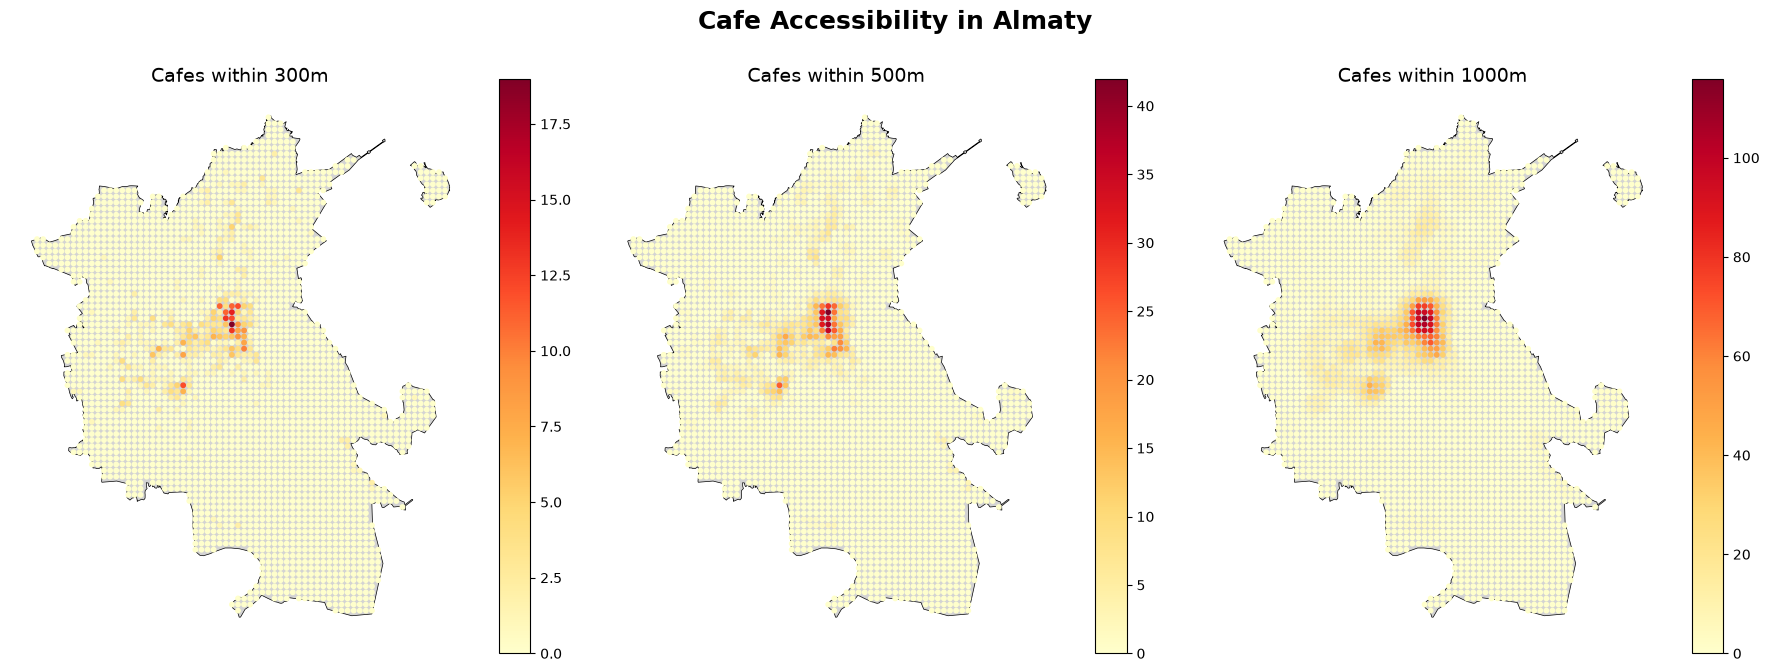

In [50]:
import matplotlib.pyplot as plt

radii = [300, 500, 1000]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, radius in zip(axes, radii):

    # Граница Алматы
    almaty_m.plot(
        ax=ax,
        color="lightgray",
        edgecolor="black",
        linewidth=0.5
    )

    # Кандидатные точки
    points_inside_city.plot(
        ax=ax,
        column=f"cafes_{radius}m",
        cmap="YlOrRd",
        legend=True,
        markersize=10
    )

    ax.set_title(f"Cafes within {radius}m", fontsize=14)
    ax.set_axis_off()

plt.suptitle(
    "Cafe Accessibility in Almaty",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## Bus Stop Feature Engineering

In [51]:
import osmnx as ox
import geopandas as gpd

place = "Almaty, Kazakhstan"
tags = {"highway" : "bus_stop"}

bus_stops = ox.features_from_place(place,tags)

In [56]:
print(bus_stops.shape)
print(bus_stops.crs)
print(bus_stops.geom_type.value_counts())
print(bus_stops.isnull().sum())


(1996, 55)
epsg:4326
Point      1995
Polygon       1
Name: count, dtype: int64
geometry                            0
highway                             0
name                              189
bench                            1082
bus                               192
name:en                          1279
name:ru                          1595
public_transport                  181
source                           1843
bin                              1231
lit                              1437
shelter                          1004
trolleybus                       1847
name:kk                          1798
departures_board                 1604
int_name                         1957
tactile_paving                   1672
level                            1945
wheelchair                       1764
name:zh                          1994
old_name                         1983
check_date:shelter               1970
covered                          1969
route_ref                        1965
check_dat

In [57]:
print(bus_stops.isna().mean())

geometry                         0.000000
highway                          0.000000
name                             0.094689
bench                            0.542084
bus                              0.096192
name:en                          0.640782
name:ru                          0.799098
public_transport                 0.090681
source                           0.923347
bin                              0.616733
lit                              0.719940
shelter                          0.503006
trolleybus                       0.925351
name:kk                          0.900802
departures_board                 0.803607
int_name                         0.980461
tactile_paving                   0.837675
level                            0.974449
wheelchair                       0.883768
name:zh                          0.998998
old_name                         0.993487
check_date:shelter               0.986974
covered                          0.986473
route_ref                        0

In [58]:
bus_stops.head()

geometry   highway  \
element id                                               
node    442563900  POINT (76.98778 43.35731)  bus_stop   
        442563902  POINT (76.98748 43.35754)  bus_stop   
        442563911  POINT (76.98452 43.34267)  bus_stop   
        442566415  POINT (76.95789 43.32033)  bus_stop   
        442566419  POINT (76.95968 43.32163)  bus_stop   

                                     name bench  bus            name:en  \
element id                                                                
node    442563900                     NaN   NaN  NaN                NaN   
        442563902                     NaN   NaN  NaN                NaN   
        442563911             Рынoк Алтай   NaN  NaN                NaN   
        442566415                 Суюнбая   yes  yes           Suyunbay   
        442566419  Өрт сөндіру бөлімі №11   NaN  yes  Fire station № 11   

                               name:ru public_transport  source  bin  ...  \
element id                                                            ...   
node    442563900                  NaN              NaN     NaN  NaN  ...   
        442563902                  NaN              NaN     NaN  NaN  ...   
        442563911                  NaN              NaN     NaN  NaN  ...   
        442566415              Суюнбая         platform  survey  NaN  ...   
        442566419  Пожарная часть № 11         platform     NaN  NaN  ...   

                  name:signed plot_number name:eb bus_bay addr:district  \
element id                                                                
node    442563900         NaN         NaN     NaN     NaN           NaN   
        442563902         NaN         NaN     NaN     NaN           NaN   
        442563911         NaN         NaN     NaN     NaN           NaN   
        442566415         NaN         NaN     NaN     NaN           NaN   
        442566419         NaN         NaN     NaN     NaN           NaN   

                  backrest seats oneway short_name note  
element id                                               
node    442563900      NaN   NaN    NaN        NaN  NaN  
        442563902      NaN   NaN    NaN        NaN  NaN  
        442563911      NaN   NaN    NaN        NaN  NaN  
        442566415      NaN   NaN    NaN        NaN  NaN  
        442566419      NaN   NaN    NaN        NaN  NaN  

[5 rows x 55 columns]

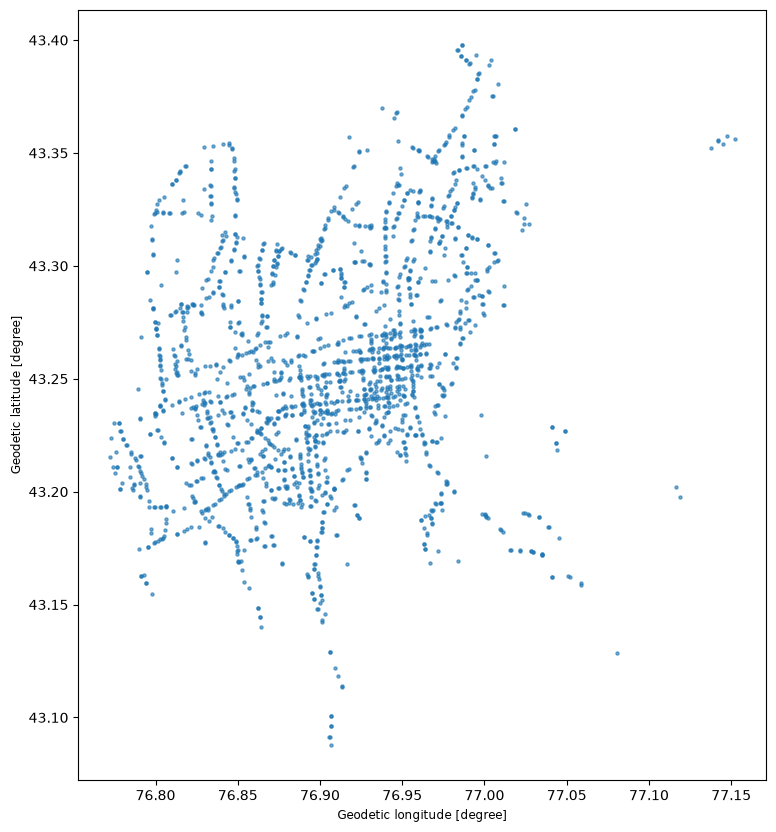

In [59]:
ax = bus_stops.plot(figsize=(10,10), markersize=5, alpha=0.6)

In [60]:
metrics_crs = bus_stops.estimate_utm_crs()

bus_stops_m = bus_stops.to_crs(metrics_crs)

print(bus_stops_m.crs)

EPSG:32643


In [61]:
bus_stops_points = bus_stops_m.copy()

bus_stops_points['geometry'] = bus_stops_points.geometry.representative_point()

In [62]:
print(bus_stops_points.crs)
print(points_inside_city.crs)
print(bus_stops_points.geom_type.value_counts())

EPSG:32643
EPSG:32643
Point    1996
Name: count, dtype: int64


In [64]:

bus_stops500m = []

for point in points_inside_city.geometry:
    result = count_nearby_cafes(point, bus_stops_points, 500)
    bus_stops500m.append(result)


print(len(bus_stops500m))
print(bus_stops500m[:10])

2822
[np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]
